# FaultTrack: data preparation, EDA and model selection

FaultTrack looks at the per-service Prometheus metrics around an alert and answers two questions: *which kind of fault is it* (`cpu`, `mem`, `disk`, `socket`, `delay` or `loss`), and *which service did it most likely start in*. Sections 1–3 (plan line 5) cover data preparation, exploratory data analysis (EDA) and an exploratory look at feature importance. Sections 4–7 (plan line 6) compare models with cross-validation grouped by case, tune them with nested grouped CV, choose the final model and evaluate it.

**Data.** [RCAEval](https://doi.org/10.5281/zenodo.14590730) RE2 (Pham et al., *RCAEval: A Benchmark for Root Cause Analysis of Microservice Systems with Telemetry Data*, WWW 2025 Companion; Zenodo DOI `10.5281/zenodo.14590730`, license [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)). RE2 has three microservice systems: Online Boutique (OB), Sock Shop (SS) and Train Ticket (TT). Each has 6 fault types injected into 5 services, 3 times each, which gives 270 cases. We changed the data as described in `data/features/ATTRIBUTION.md`: we kept only `simple_metrics.csv` and computed shift features from it.

**What this notebook reads.** Only committed files, so it runs on a fresh clone without the 4 GB download: `data/features/re2_features.parquet` (1,350 rows of features), `data/features/re2_inventory.parquet` (one row per case folder) and the small real case in `tests/fixtures/`. All features come from `src/faulttrack/features.py`; nothing is re-implemented here.

**Run it.** `uv sync`, then `uv run jupyter nbconvert --to notebook --execute --inplace notebook.ipynb`.

In [1]:
import itertools
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_selection import mutual_info_classif

from faulttrack.data import FAULTS, KINDS, clean_metrics, read_metrics
from faulttrack.features import (
    BASELINE_S,
    DELAYS_S,
    FEATURE_NAMES,
    POST_S,
    shift_scores,
)

SEED = 42
np.random.seed(SEED)

ROOT = Path.cwd()
if not (ROOT / "data" / "features").is_dir():  # started from a subfolder
    ROOT = ROOT.parent

SYSTEM_NAMES = {"re2ob": "OB", "re2ss": "SS", "re2tt": "TT"}


# Relabel a table's system index (re2ob, ...) with the short names.
def short_names(table: pd.DataFrame) -> pd.DataFrame:
    return table.set_axis([SYSTEM_NAMES[str(s)] for s in table.index], axis="index")


# Number of True values in a boolean mask.
def count(mask: Any) -> int:
    return int(mask.to_numpy().sum())


# Median of a column over the rows selected by a boolean mask.
def med(frame: pd.DataFrame, mask: Any, column: str) -> float:
    return float(np.median(frame.loc[mask, column].to_numpy(dtype=float)))


# Share of the selected rows where a column is above 0.
def share_pos(frame: pd.DataFrame, mask: Any, column: str) -> float:
    return float((frame.loc[mask, column].to_numpy(dtype=float) > 0).mean())


# Format a column's median and (min-max) as text.
def median_range(values: pd.Series) -> str:
    arr = values.to_numpy(dtype=float)
    return f"{np.median(arr):.0f} ({arr.min():.0f}-{arr.max():.0f})"


SYSTEM_COLORS = {"re2ob": "#0072B2", "re2ss": "#E69F00", "re2tt": "#009E73"}
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
    }
)

features: pd.DataFrame = pd.read_parquet(
    ROOT / "data" / "features" / "re2_features.parquet"
)
inventory: pd.DataFrame = pd.read_parquet(
    ROOT / "data" / "features" / "re2_inventory.parquet"
)
print(f"feature table: {features.shape[0]} rows x {features.shape[1]} columns")
print(
    f"inventory:     {inventory.shape[0]} case folders x {inventory.shape[1]} columns"
)

feature table: 1350 rows x 55 columns
inventory:     270 case folders x 20 columns


Both tables loaded: the feature table has one row per case and detection delay, and the inventory has one row per case folder with its sizes, column counts and missing-value counts.

## 1. Data preparation

**What a case is.** A case is one fault injected into one service of one system, for example `re2ob/productcatalogservice_cpu/1`. The folder name gives the label (`<service>_<fault>`), and each case has a `simple_metrics.csv` with 1,441 rows at 1 s (24 minutes) and the fault injected at the midpoint, plus `inject_time.txt`.

**Rows.** An alert doesn't fire at the instant of the fault, so each case gives 5 rows, at detection delays of 0, 30, 60, 90 and 120 s after the injection. For a detection time `t_det`, the baseline is the 300 s before `t_det` and the post window is the 120 s after it. The features are the shift of each metric from baseline to post window (a z-score scaled by the baseline's MAD, log-compressed), summarized per metric kind across services. The 5 rows of a case are near-duplicates, so every evaluation later has to be grouped by `case_id`.

In [2]:
example_id = "re2ob/productcatalogservice_cpu/1"
display(
    features.loc[
        features["case_id"] == example_id,
        ["case_id", "delay_s", "fault", "suspect_service", "cpu_max", "mem_max"]
        + ["latency_max", "top_cpu_share"],
    ].round(2)
)
n_cases = features["case_id"].nunique()
print(f"{n_cases} cases x {len(DELAYS_S)} delays {DELAYS_S} s = {len(features)} rows")

,case_id,delay_s,fault,suspect_service,cpu_max,mem_max,latency_max,top_cpu_share
270,re2ob/productcatalogservice_cpu/1,0,cpu,productcatalogservice,4.65,3.49,6.84,0.24
271,re2ob/productcatalogservice_cpu/1,30,cpu,productcatalogservice,4.58,3.15,6.84,0.28
272,re2ob/productcatalogservice_cpu/1,60,cpu,productcatalogservice,4.36,2.85,6.86,0.28
273,re2ob/productcatalogservice_cpu/1,90,cpu,productcatalogservice,4.30,2.30,6.86,0.29
274,re2ob/productcatalogservice_cpu/1,120,cpu,productcatalogservice,3.76,1.98,6.45,0.28


270 cases x 5 delays (0, 30, 60, 90, 120) s = 1350 rows


The 5 rows of one case differ only in the detection delay: the shifts shrink slowly as the delay grows, because the baseline starts to include fault data. In all, 270 cases give 1,350 rows.

**Dataset quirks.** `faulttrack.data` handles all of these, so no caller has to:

| Quirk | How it is handled |
|---|---|
| Train Ticket names start with `ts-`; Sock Shop's frontend is `front-end` | Kept as is. A column's service is the text before the first `_` |
| `inf` values and gaps | `inf` becomes NaN, then forward-fill, then 0 |
| Repeated header column `time.1` in some suites | Dropped |
| Rows with an empty `time` (two RE2-OB files) | Dropped, because they can't be placed in a window |
| `latency-50` columns | Ignored: only the p90 latency (`latency-90`) is used, as in RCAEval's own baselines |
| A service and its database (`carts`, `carts-db`) | One service; the larger of the two shifts is kept (`docs/decisions.md`) |
| `checkoutservice_cpu/multi-source-data/` in RE2-OB | Not a numbered case; ignored |
| A case with no `simple_metrics.csv`, or an unreadable one | Skipped with a message on stderr, never filled silently |

In [3]:
FIXTURE = ROOT / "tests" / "fixtures"
raw = read_metrics(FIXTURE / "simple_metrics.csv")
clean = clean_metrics(raw)
dropped = sorted(set(raw.columns) - set(clean.columns))
print(f"raw columns: {raw.shape[1]}, cleaned columns: {clean.shape[1]}")
print(f"dropped by clean_metrics: {dropped}")

raw columns: 72, cleaned columns: 62
dropped by clean_metrics: ['adservice_latency-50', 'cartservice_latency-50', 'checkoutservice_latency-50', 'currencyservice_latency-50', 'emailservice_latency-50', 'frontend_latency-50', 'paymentservice_latency-50', 'productcatalogservice_latency-50', 'recommendationservice_latency-50', 'shippingservice_latency-50']


On the real fixture case (RE2-OB, `productcatalogservice_cpu/1`), cleaning drops the 10 `latency-50` columns and keeps `time` plus 61 metric columns.

In [4]:
quirk_rows = {
    "cases in the inventory": len(inventory),
    "status ok": count(inventory["status"] == "ok"),
    "skipped (status not ok)": count(inventory["status"] != "ok"),
    "cases with untimed rows (dropped)": count(inventory["n_untimed_rows"] > 0),
    "cases with fewer than 1,441 rows": count(inventory["n_rows"] < 1441),
    "cases with any NaN before filling": count(inventory["nan_pct"] > 0),
    "cases with any inf": count(inventory["inf_count"] > 0),
}
display(pd.Series(quirk_rows, name="count").to_frame())
display(
    inventory.loc[
        (inventory["n_untimed_rows"] > 0) | (inventory["n_rows"] < 1441),
        ["case_id", "n_rows", "n_untimed_rows", "inject_pos", "nan_pct"],
    ].round(2)
)
skipped = inventory[inventory["status"] != "ok"]
print("skipped cases:", "none" if skipped.empty else skipped["case_id"].tolist())

,count
cases in the inventory,270
status ok,270
skipped (status not ok),0
cases with untimed rows (dropped),2
"cases with fewer than 1,441 rows",2
cases with any NaN before filling,245
cases with any inf,0


,case_id,n_rows,n_untimed_rows,inject_pos,nan_pct
1,re2ob/checkoutservice_cpu/2,1186,256,0.78,17.32
13,re2ob/checkoutservice_mem/2,1262,258,0.72,15.84


skipped cases: none


All 270 cases are usable and none is skipped. Two RE2-OB cases (`checkoutservice_cpu/2` and `checkoutservice_mem/2`) end with 256 and 258 rows that have no `time`; after dropping them, 930 and 1,004 timed rows remain, and the injection falls at 78% and 72% of the file instead of 50%. Every window still fits. Most cases (245 of 270) have some missing cells before filling, and no case has an `inf` value in `simple_metrics.csv`, so the `inf` rule is a safeguard for other data.

## 2. Exploratory data analysis

### 2.1 Target: class balance

In [5]:
cases = inventory[inventory["status"] == "ok"]
balance = pd.crosstab(cases["system"], cases["fault"])[list(FAULTS)]
balance["all faults"] = balance.sum(axis=1)
balance.loc["all systems"] = balance.sum()
display(balance)

fault,cpu,mem,disk,socket,delay,loss,all faults
system,,,,,,,
re2ob,15,15,15,15,15,15,90
re2ss,15,15,15,15,15,15,90
re2tt,15,15,15,15,15,15,90
all systems,45,45,45,45,45,45,270


Number of cases per system and fault type. The classes are exactly balanced: 15 cases per fault per system, 45 per fault overall (225 of the 1,350 rows each), so no resampling or class weights are needed.

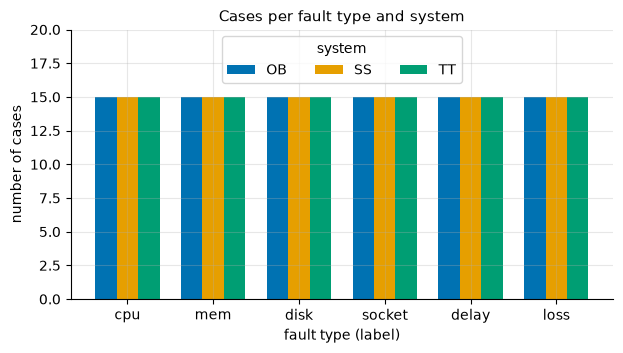

In [6]:
per_fault = balance.drop(index="all systems").drop(columns="all faults")
fig, ax = plt.subplots(figsize=(7, 3.5))
width = 0.25
x = np.arange(len(FAULTS))
for k, (system, row) in enumerate(per_fault.iterrows()):
    ax.bar(
        x + (k - 1) * width,
        row.to_numpy(),
        width,
        label=SYSTEM_NAMES[str(system)],
        color=SYSTEM_COLORS[str(system)],
    )
ax.set_xticks(x, list(FAULTS))
ax.set_ylim(0, 20)
ax.set_xlabel("fault type (label)")
ax.set_ylabel("number of cases")
ax.set_title("Cases per fault type and system")
ax.legend(title="system", ncol=3, loc="upper center")
plt.show()

The same counts as a chart. The balance comes from the injection protocol, not from real incident rates, so a deployed model would see an uneven mix of faults; we state this as a limitation.

### 2.2 Raw-data ranges and missing values

In [7]:
ranges = cases.groupby("system").agg(
    cases=("case_id", "size"),
    rows_min=("n_rows", "min"),
    rows_median=("n_rows", "median"),
    metric_cols_min=("n_metric_cols", "min"),
    metric_cols_median=("n_metric_cols", "median"),
    metric_cols_max=("n_metric_cols", "max"),
    nan_pct_median=("nan_pct", "median"),
    nan_pct_max=("nan_pct", "max"),
    inf_total=("inf_count", "sum"),
    inject_pos_min=("inject_pos", "min"),
    inject_pos_max=("inject_pos", "max"),
)
display(ranges.round(3).T)

system,re2ob,re2ss,re2tt
cases,90,90,90
rows_min,1186,1441,1441
rows_median,1441.0,1441.0,1441.0
metric_cols_min,59,67,318
metric_cols_median,64.0,69.0,334.5
metric_cols_max,67,75,348
nan_pct_median,0.004,0.018,0.31
nan_pct_max,17.321,11.135,4.244
inf_total,0,0,0
inject_pos_min,0.5,0.5,0.5


Raw-file sizes by system (`n_rows` counts every row in the file, including untimed ones; `nan_pct` is the share of missing metric cells in the raw file). The systems differ most in width: about 64 metric columns for OB, 69 for SS and 335 for TT after cleaning. Missing values are rare except in TT (median 0.31% of cells) and in the two OB cases with untimed rows (up to 17.3%).

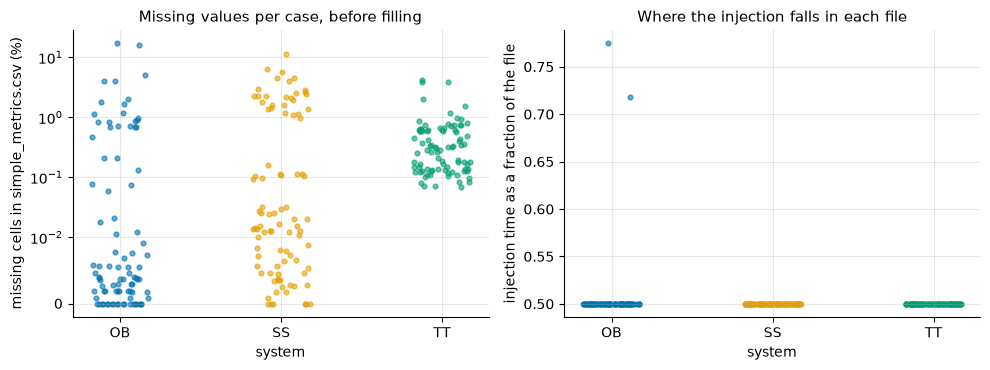

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
rng = np.random.default_rng(SEED)
for k, system in enumerate(SYSTEM_NAMES):
    sub = cases[cases["system"] == system]
    jitter = rng.uniform(-0.18, 0.18, len(sub))
    axes[0].scatter(
        k + jitter,
        sub["nan_pct"],
        s=12,
        alpha=0.6,
        color=SYSTEM_COLORS[system],
    )
    axes[1].scatter(
        k + jitter,
        sub["inject_pos"],
        s=12,
        alpha=0.6,
        color=SYSTEM_COLORS[system],
    )
labels = [SYSTEM_NAMES[s] for s in SYSTEM_NAMES]
axes[0].set_yscale("symlog", linthresh=0.01)
axes[0].set_ylabel("missing cells in simple_metrics.csv (%)")
axes[0].set_title("Missing values per case, before filling")
axes[1].set_ylabel("injection time as a fraction of the file")
axes[1].set_title("Where the injection falls in each file")
for ax in axes:
    ax.set_xticks(range(3), labels)
    ax.set_xlabel("system")
plt.tight_layout()
plt.show()

Each dot is one case (the left axis is linear below 0.01% and logarithmic above). Most cases are missing under 1% of cells. SS splits into two groups, one near 0.01% and one at 1-10%, and TT cases all have some missing cells (about 0.07-4%). The injection sits at the midpoint (0.5) of every file except the two OB cases with untimed rows, so the detection windows always start inside the file.

### 2.3 Telemetry coverage and system size

In [9]:
cols_per_kind = pd.DataFrame(
    {
        kind: {
            system: median_range(
                inventory.loc[inventory["system"] == system, f"n_cols_{kind}"]
            )
            for system in SYSTEM_NAMES
        }
        for kind in KINDS
    }
)
display(short_names(cols_per_kind))

,cpu,mem,diskio,socket,latency,error,workload
OB,11 (11-11),11 (11-12),7 (4-9),11 (11-12),10 (10-10),3 (0-4),11 (10-13)
SS,15 (15-15),15 (15-16),8 (7-10),15 (15-16),7 (7-7),2 (0-6),7 (7-7)
TT,68 (68-68),68 (68-69),67 (67-67),68 (68-69),28 (22-28),8 (0-21),28 (22-28)


Metric columns per kind in `simple_metrics.csv`: median (min-max) over cases. The kinds are far from complete. Only 2-3 services export `error` in OB and SS (8 in TT), and `diskio` is missing for several services in OB and SS but present for almost every service in TT.

In [10]:
at_delay_0 = features.loc[features["delay_s"] == 0]
services_per_kind = pd.DataFrame(
    {
        kind: {
            system: int(
                med(at_delay_0, at_delay_0["system"] == system, f"n_services_{kind}")
            )
            for system in SYSTEM_NAMES
        }
        for kind in KINDS
    }
)
display(short_names(services_per_kind))

,cpu,mem,diskio,socket,latency,error,workload
OB,11,11,7,11,10,3,11
SS,11,11,7,11,7,2,7
TT,68,68,67,68,28,8,28


Services per kind as the features count them, after a service and its `-db` are merged into one. The systems have 11 (OB), 11 (SS) and 68 (TT) services after this merge. Before it, SS has 15 services (15 CPU columns), because 4 databases count separately. TT is about 6 times larger than the other two, which is why count-type features (`*_abssum`, `*_n_gt3`) can't be compared directly across systems.

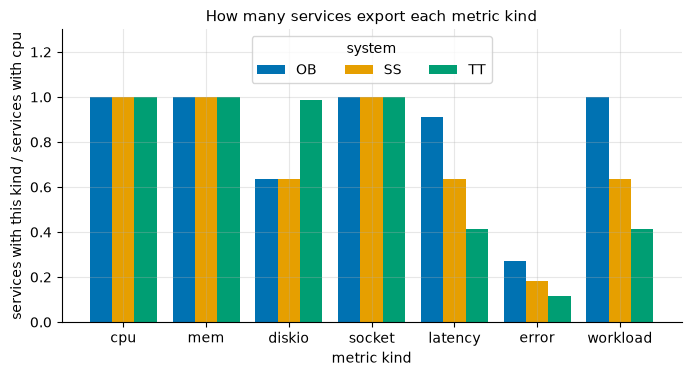

In [11]:
coverage = services_per_kind.div(services_per_kind["cpu"], axis=0)
fig, ax = plt.subplots(figsize=(8, 3.8))
width = 0.27
x = np.arange(len(KINDS))
for k, (system, row) in enumerate(coverage.iterrows()):
    ax.bar(
        x + (k - 1) * width,
        row.to_numpy(),
        width,
        label=SYSTEM_NAMES[str(system)],
        color=SYSTEM_COLORS[str(system)],
    )
ax.set_xticks(x, list(KINDS))
ax.set_ylim(0, 1.3)
ax.set_xlabel("metric kind")
ax.set_ylabel("services with this kind / services with cpu")
ax.set_title("How many services export each metric kind")
ax.legend(title="system", ncol=3, loc="upper center")
plt.show()

Coverage as a share of the services that export `cpu`. `cpu`, `mem` and `socket` cover every service. `diskio` covers 7 of 11 OB services and 7 of 11 SS services (64%), but 67 of 68 TT services (99%). Latency and workload cover most OB services (91% and 100%) but fewer in SS (64%) and TT (41%), and `error` covers only 12-27% of services in every system.

In [12]:
disk = at_delay_0.loc[at_delay_0["fault"] == "disk"]
other = at_delay_0.loc[at_delay_0["fault"] != "disk"]


# Share of rows of one system where diskio clearly shifted (z above 3).
def share_shifted(frame: pd.DataFrame, system: str) -> float:
    sub = frame.loc[frame["system"] == system, "diskio_n_gt3"]
    return float((sub.to_numpy(dtype=float) > 0).mean())


# Median of a column over the rows of one system.
def median_of(frame: pd.DataFrame, system: str, column: str) -> float:
    sub = frame.loc[frame["system"] == system, column]
    return float(np.median(sub.to_numpy(dtype=float)))


gap = pd.DataFrame(
    {
        system: {
            "disk cases": int((disk["system"] == system).sum()),
            "services with diskio": median_of(disk, system, "n_services_diskio"),
            "services with cpu": median_of(disk, system, "n_services_cpu"),
            "diskio clearly shifted, disk faults": share_shifted(disk, system),
            "diskio clearly shifted, other faults": share_shifted(other, system),
            "median mem_max, disk faults": median_of(disk, system, "mem_max"),
            "median cpu_max, disk faults": median_of(disk, system, "cpu_max"),
        }
        for system in SYSTEM_NAMES
    }
).T
display(short_names(gap).round(2))

,disk cases,services with diskio,services with cpu,"diskio clearly shifted, disk faults","diskio clearly shifted, other faults","median mem_max, disk faults","median cpu_max, disk faults"
OB,15.0,6.0,11.0,0.27,0.03,6.30,4.67
SS,15.0,7.0,11.0,0.07,0.05,8.36,5.95
TT,15.0,67.0,68.0,1.00,0.23,4.71,3.32


**The disk telemetry gap.** For disk faults (delay 0), `diskio` clearly shifts (by more than 3 in z) in only 27% of OB cases and 7% of SS cases, against 100% of TT cases, while the memory shift (`mem_max`) is large everywhere (4.7 to 8.4). In OB and SS the injected disk stress mostly shows up as memory and CPU (page cache), not as disk I/O, so a disk fault there looks like a memory fault. The go/no-go spike on the raw files found that only 2 of the 5 disk-fault services in OB export `diskio` at all (spec §5.3); the committed tables only count columns per case, so we don't recompute that figure here.

### 2.4 Feature ranges

,min,25%,50%,75%,max
cpu_max,-3.53,1.15,3.45,5.24,9.08
mem_max,-2.76,1.02,2.71,5.22,9.53
diskio_max,-2.07,-0.16,0.53,1.09,13.76
socket_max,-4.42,0.00,1.36,2.17,6.78
latency_max,-4.61,3.82,6.02,7.55,11.33
error_max,-0.62,0.00,0.00,0.00,4.64
workload_max,-3.47,-0.93,-0.60,0.45,2.36


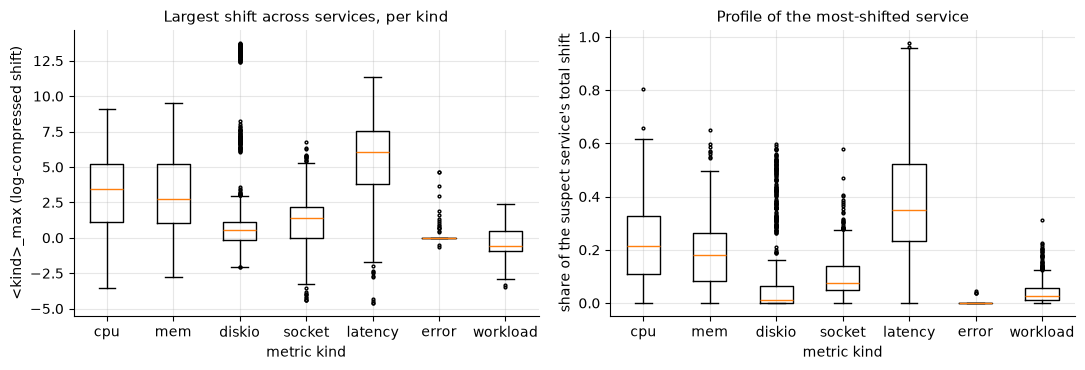

In [13]:
max_cols = [f"{k}_max" for k in KINDS]
share_cols = [f"top_{k}_share" for k in KINDS]
display(features[max_cols].describe().T[["min", "25%", "50%", "75%", "max"]].round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].boxplot(
    [features[c] for c in max_cols], tick_labels=list(KINDS), flierprops={"ms": 2}
)
axes[0].set_xlabel("metric kind")
axes[0].set_ylabel("<kind>_max (log-compressed shift)")
axes[0].set_title("Largest shift across services, per kind")
axes[1].boxplot(
    [features[c] for c in share_cols], tick_labels=list(KINDS), flierprops={"ms": 2}
)
axes[1].set_xlabel("metric kind")
axes[1].set_ylabel("share of the suspect service's total shift")
axes[1].set_title("Profile of the most-shifted service")
plt.tight_layout()
plt.show()

Shift features are log-compressed z-scores, so they stay in a narrow range (about -5 to +14 here) instead of spanning orders of magnitude. A clear shift (z above 3) is 1.39 on this scale. `latency_max` is typically the largest (median 6.0), `cpu_max` and `mem_max` are next (3.5 and 2.7), and `workload_max` is mostly negative (median -0.6). `error_max` is exactly 0 in 99% of rows because few services export `error` and it almost never shifts. The shares (right) are fractions between 0 and 1 that sum to 1 across kinds for the suspect service.

### 2.5 Fault signatures

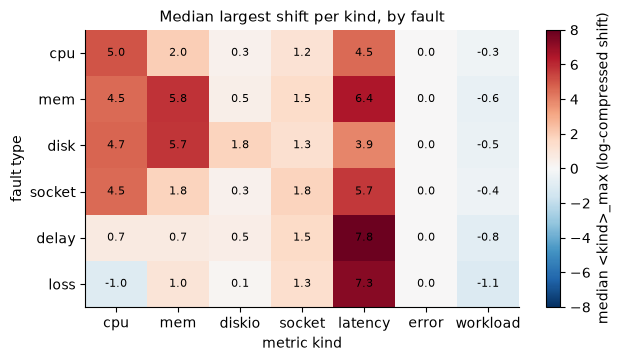

In [14]:
signature = pd.DataFrame(
    {
        kind: {
            fault: med(features, features["fault"] == fault, f"{kind}_max")
            for fault in FAULTS
        }
        for kind in KINDS
    }
)
reach = pd.DataFrame(
    {
        kind: {
            fault: share_pos(features, features["fault"] == fault, f"{kind}_n_gt3")
            for fault in FAULTS
        }
        for kind in KINDS
    }
)


def heatmap(ax, data, title, cmap, vmin, vmax, fmt):
    image = ax.imshow(data.to_numpy(), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(data.shape[1]), list(data.columns))
    ax.set_yticks(range(data.shape[0]), list(data.index))
    for i, j in itertools.product(range(data.shape[0]), range(data.shape[1])):
        ax.text(j, i, format(data.iat[i, j], fmt), ha="center", va="center", fontsize=8)
    ax.grid(False)
    ax.set_title(title)
    ax.set_xlabel("metric kind")
    ax.set_ylabel("fault type")
    return image


fig, ax = plt.subplots(figsize=(7, 3.6))
img = heatmap(
    ax,
    signature,
    "Median largest shift per kind, by fault",
    "RdBu_r",
    -8,
    8,
    ".1f",
)
fig.colorbar(img, ax=ax, label="median <kind>_max (log-compressed shift)")
plt.show()

Median of each `<kind>_max` by fault, over all 1,350 rows (red is a rise, blue a drop). Reading the rows:

- **cpu:** CPU rises most (5.0), memory barely (2.0), latency follows (4.5).
- **mem:** memory (5.8) and CPU (4.5) both rise, and latency is high (6.4).
- **disk:** looks like `mem`: memory 5.7, CPU 4.7. Disk I/O is the only extra sign (1.8), and it is weak (see 2.3).
- **socket:** the socket count rises only modestly (1.8), CPU (4.5) and latency (5.7) rise more, and memory stays low.
- **delay:** latency is the largest (7.8) while CPU and memory hardly move (0.7).
- **loss:** latency also rises (7.3), but CPU drops (-1.0) and workload falls most (-1.1).

Two pairs look hard to separate from these medians alone: `mem` vs `disk`, and `delay` vs `loss`. We check this against the model's confusion matrix in the modeling section.

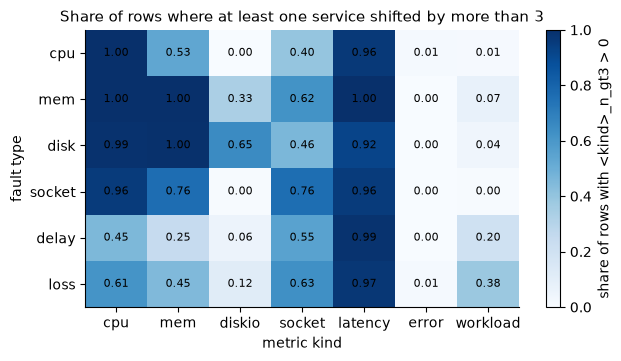

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.6))
img = heatmap(
    ax,
    reach,
    "Share of rows where at least one service shifted by more than 3",
    "Blues",
    0,
    1,
    ".2f",
)
fig.colorbar(img, ax=ax, label="share of rows with <kind>_n_gt3 > 0")
plt.show()

How often each kind shows a clear shift for each fault. Latency shifts in at least 92% of rows for every fault, so it says "something is wrong" but not what. CPU separates `cpu`, `mem`, `disk` and `socket` (96-100%) from `delay` (45%) and `loss` (61%). Memory separates `mem` and `disk` (100%) from `cpu` (53%), `socket` (76%) and the network faults (25-45%). `error` almost never shifts (at most 1%).

In [16]:
by_delay = pd.DataFrame(
    {
        kind: {
            delay: float(
                np.median(
                    np.abs(
                        features.loc[
                            features["delay_s"] == delay, f"{kind}_max"
                        ].to_numpy(dtype=float)
                    )
                )
            )
            for delay in DELAYS_S
        }
        for kind in KINDS
    }
)
display(by_delay.round(2))

,cpu,mem,diskio,socket,latency,error,workload
0,4.03,2.94,0.59,2.47,6.51,0.0,0.78
30,4.03,2.69,0.75,1.65,6.29,0.0,0.77
60,3.65,2.76,0.71,1.40,5.97,0.0,0.78
90,3.34,2.80,0.71,1.32,5.70,0.0,0.75
120,2.97,2.70,0.69,1.29,5.34,0.0,0.76


Median size of `<kind>_max` by detection delay. The shifts get smaller as the delay grows (for example `cpu` from 4.0 at 0 s to 3.0 at 120 s, and `latency` from 6.5 to 5.3), because the baseline then already contains some fault data. The shift is still clear at 120 s. This is expected and matches a real alert that fires late.

### 2.6 One raw case

most-shifted metrics: ['productcatalogservice_latency-90', 'recommendationservice_latency-90', 'productcatalogservice_cpu', 'productcatalogservice_socket']


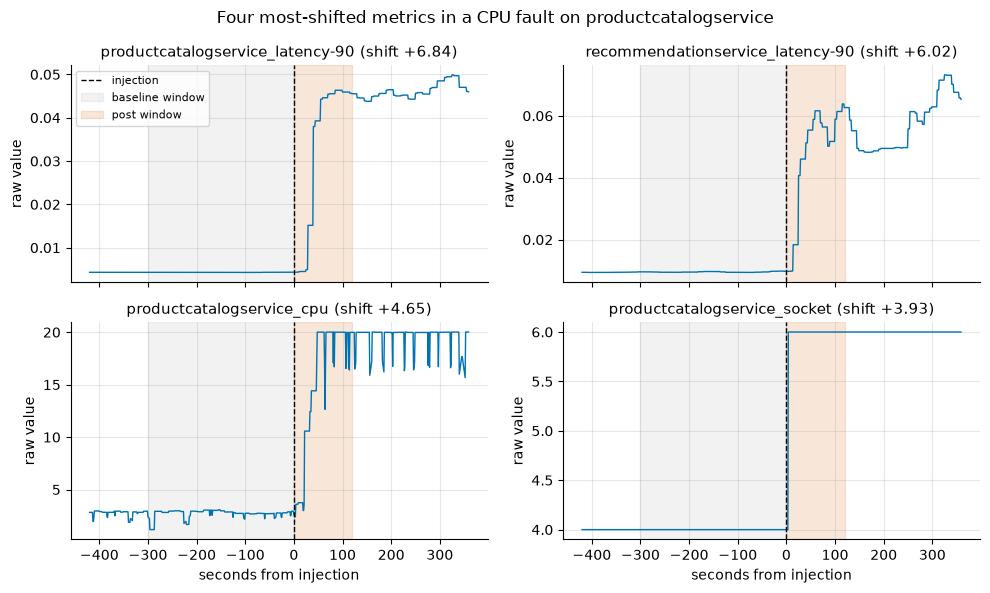

In [17]:
inject_time = int((FIXTURE / "inject_time.txt").read_text().strip())
times = clean["time"]
baseline = clean.loc[(times >= inject_time - BASELINE_S) & (times < inject_time)]
post = clean.loc[(times >= inject_time) & (times < inject_time + POST_S)]
shift = shift_scores(baseline.drop(columns="time"), post.drop(columns="time"))
top4 = [str(c) for c in shift.abs().sort_values(ascending=False).head(4).index]
print("most-shifted metrics:", top4)

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, column in zip(axes.ravel(), top4, strict=True):
    ax.plot(clean["time"] - inject_time, clean[column], lw=1, color="#0072B2")
    ax.axvline(0, color="black", ls="--", lw=1, label="injection")
    ax.axvspan(-BASELINE_S, 0, color="#999999", alpha=0.12, label="baseline window")
    ax.axvspan(0, POST_S, color="#D55E00", alpha=0.15, label="post window")
    ax.set_title(f"{column} (shift {shift[column]:+.2f})")
    ax.set_ylabel("raw value")
for ax in axes[1]:
    ax.set_xlabel("seconds from injection")
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("Four most-shifted metrics in a CPU fault on productcatalogservice")
plt.tight_layout()
plt.show()

One real case: a CPU fault on `productcatalogservice` (RE2-OB). Right after the dashed injection line, the p90 latency of the injected service jumps from about 0.004 to 0.045 and the latency of `recommendationservice` also rises. The injected service's CPU climbs from about 3 to 20 and stays there, and its socket count steps from 4 to 6. The number in each title is the shift: the median of the orange post window against the median of the gray baseline window, in units of baseline noise, log-compressed. The raw values sit on very different scales (0.004, 3, 4), which is why the features use shifts and not raw values.

### 2.7 Why the scale floor and log compression matter

In [18]:
base_only = baseline.drop(columns="time")
post_only = post.drop(columns="time")
z_plain = shift_scores(base_only, post_only, z_floor=0, log_z=False)
z_default = shift_scores(base_only, post_only)
injected = "productcatalogservice_cpu"
compare = pd.DataFrame(
    {
        "baseline median": base_only.median(),
        "plain z": z_plain,
        "default shift": z_default,
        "rank (plain)": z_plain.abs().rank(ascending=False).astype(int),
        "rank (default)": z_default.abs().rank(ascending=False).astype(int),
    }
)
display(compare.sort_values("rank (plain)").head(8).round(2))
print(
    f"{injected}: rank {compare.loc[injected, 'rank (plain)']} with plain z, ", end=""
)
print(f"rank {compare.loc[injected, 'rank (default)']} with the default shift")

,baseline median,plain z,default shift,rank (plain),rank (default)
productcatalogservice_latency-90,0.00,1000.00,6.84,1,1
recommendationservice_latency-90,0.01,408.95,6.02,2,2
productcatalogservice_cpu,2.82,103.56,4.65,3,3
productcatalogservice_mem,10174464.00,31.63,3.49,4,5
recommendationservice_mem,46358528.00,-2.70,-0.10,5,36
frontend_latency-90,0.62,-2.38,-1.22,6,6
emailservice_workload,0.73,2.35,1.21,7,7
adservice_latency-90,0.00,2.11,0.34,8,26


productcatalogservice_cpu: rank 3 with plain z, rank 3 with the default shift


The same fixture case scored two ways: plain z (no scale floor, no log compression; clipped at 1000) and the default shift. Plain z reaches 1000 for a latency column whose baseline median is about 0, and 104 for the injected CPU column, so one near-constant metric can dominate any sum or maximum. The default shift puts the same columns at 6.8 and 4.6. The injected CPU column ranks third either way here, but near-constant columns such as `recommendationservice_mem` (rank 5 with plain z, rank 36 with the default) and `adservice_latency-90` (8 and 26) no longer crowd the top. In the go/no-go spike, this change took logistic regression on OB from 0.54 to 0.85 macro F1 (spec §5.3); we don't re-measure it here because this notebook trains no models.

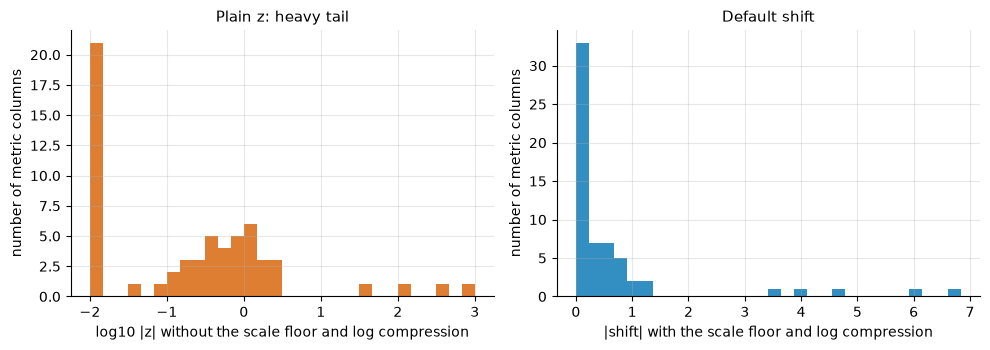

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(
    np.log10(z_plain.abs().clip(lower=1e-2)), bins=30, color="#D55E00", alpha=0.8
)
axes[0].set_xlabel("log10 |z| without the scale floor and log compression")
axes[0].set_ylabel("number of metric columns")
axes[0].set_title("Plain z: heavy tail")
axes[1].hist(z_default.abs(), bins=30, color="#0072B2", alpha=0.8)
axes[1].set_xlabel("|shift| with the scale floor and log compression")
axes[1].set_ylabel("number of metric columns")
axes[1].set_title("Default shift")
plt.tight_layout()
plt.show()

Distribution of the shift over all 61 metric columns of the case. Left: plain z on a log scale (values at or below 0.01 pile up in the first bin) has a tail out to 1000. Right: the default shift stays below 7, most columns are under 1.4, and only five columns have a shift above 3.

## 3. Feature importance (exploratory)

Mutual information (MI) measures how much a single feature tells us about the fault label, with no model involved. We estimate it with scikit-learn (`random_state=42`) on all 1,350 rows. This is a descriptive look, not an evaluation: the 5 rows of a case are near-duplicates, so the values are somewhat optimistic, and any feature selection that matters will happen inside grouped CV in the modeling section. The most MI one feature can carry is the label entropy, ln 6 = 1.79 nats.

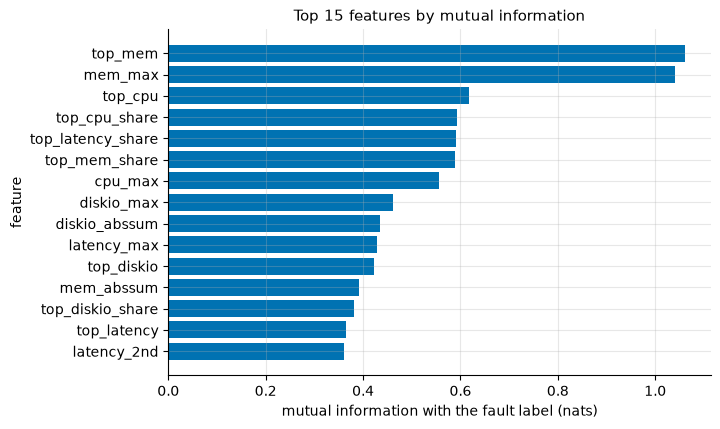

,mutual_info
top_mem,1.061
mem_max,1.041
top_cpu,0.618
top_cpu_share,0.592
top_latency_share,0.591
top_mem_share,0.588
cpu_max,0.556
diskio_max,0.461
diskio_abssum,0.435
latency_max,0.428


lowest five: {'top_error_share': 0.042, 'top_error': 0.027, 'error_2nd': 0.003, 'error_n_gt3': 0.001, 'error_abssum': 0.001}


In [20]:
mi = pd.Series(
    mutual_info_classif(features[FEATURE_NAMES], features["fault"], random_state=SEED),
    index=FEATURE_NAMES,
    name="mutual_info",
).sort_values(ascending=False)
top15 = mi.head(15)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top15.index[::-1], top15.to_numpy()[::-1], color="#0072B2")
ax.set_xlabel("mutual information with the fault label (nats)")
ax.set_ylabel("feature")
ax.set_title("Top 15 features by mutual information")
plt.show()
display(mi.head(15).round(3).to_frame())
print("lowest five:", mi.tail(5).round(3).to_dict())

The two memory features carry the most information (`top_mem` 1.06 and `mem_max` 1.04 nats, well over half of the 1.79 maximum), consistent with the heatmap: memory splits `mem` and `disk` from the other four faults. Next come CPU and the profile shares (0.56-0.62). The `diskio` features rank 8th, 9th, 11th and 13th, which is probably driven by TT, where disk I/O shifts strongly for disk faults (2.3); 3.1 checks this by system. The five lowest features are all `error` features (at most 0.04), so they carry almost no information.

In [21]:
kind_of_feature = {n: n.removeprefix("top_").split("_")[0] for n in FEATURE_NAMES}
by_kind = pd.Series(
    {
        kind: float(
            np.mean([mi[n] for n in FEATURE_NAMES if kind_of_feature[n] == kind])
        )
        for kind in KINDS
    },
    name="mean mutual information",
)
display(by_kind.round(3).to_frame())

,mean mutual information
cpu,0.399
mem,0.600
diskio,0.386
socket,0.199
latency,0.336
error,0.020
workload,0.158


Mean MI per metric kind. Memory is the most informative kind (0.60), then CPU (0.40), `diskio` (0.39) and latency (0.34). Socket (0.20) and workload (0.16) say less, and `error` (0.02) almost nothing.

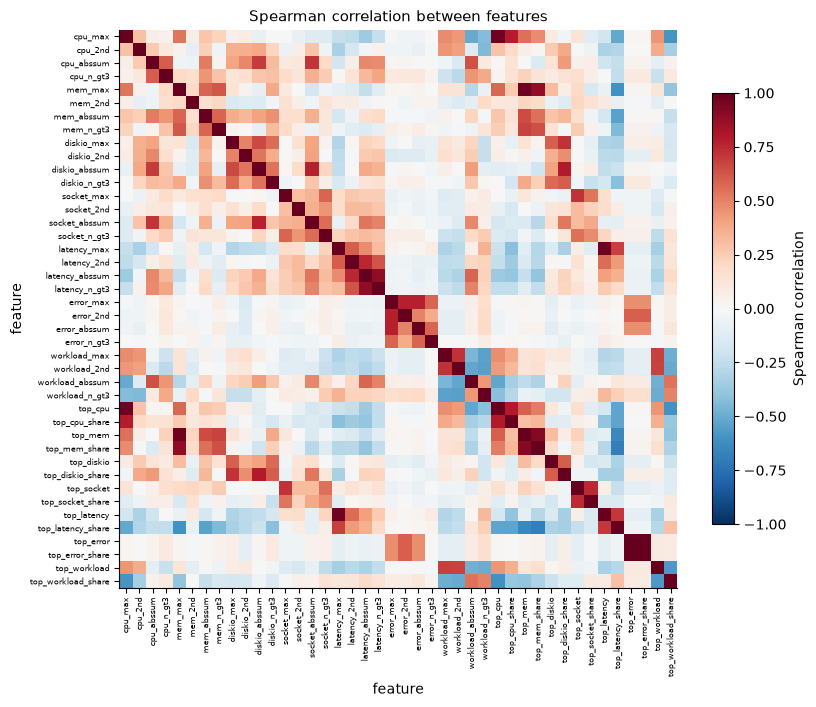

In [22]:
corr = pd.DataFrame(features[FEATURE_NAMES]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, rotation=90, fontsize=6)
ax.set_yticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, fontsize=6)
ax.grid(False)
ax.set_title("Spearman correlation between features")
ax.set_xlabel("feature")
ax.set_ylabel("feature")
fig.colorbar(image, ax=ax, shrink=0.7, label="Spearman correlation")
plt.show()

Spearman correlation between the 42 model features. Most pairs are only weakly correlated. The visible blocks are within a kind (for example the four `diskio` aggregates, or `latency_abssum` with `latency_n_gt3`) and between a kind's `_max` and the suspect service's `top_` value. The `top_*_share` features are negatively correlated with each other, because the shares of one service sum to 1.

In [23]:
pairs = pd.DataFrame(
    [
        (a, b, corr.loc[a, b])
        for a, b in itertools.combinations(FEATURE_NAMES, 2)
        if abs(corr.loc[a, b]) >= 0.9
    ],
    columns=["feature a", "feature b", "spearman"],
).sort_values("spearman", key=abs, ascending=False)
print(f"{len(pairs)} feature pairs with |rho| >= 0.9")
display(pairs.round(2).reset_index(drop=True))

5 feature pairs with |rho| >= 0.9


,feature a,feature b,spearman
0,top_error,top_error_share,1.00
1,cpu_max,top_cpu,0.98
2,latency_max,top_latency,0.98
3,mem_max,top_mem,0.97
4,top_mem,top_mem_share,0.92


Only 5 of the 861 feature pairs have |rho| of 0.9 or more. Three are `<kind>_max` with the suspect service's `top_<kind>` (CPU, memory, latency): the most-shifted service is usually the one with the largest shift. One is `top_mem` with `top_mem_share`, and one is the two `error` features, which are almost always 0. The features aren't heavily redundant. Tree models don't mind correlated inputs, but the logistic regression coefficients in the modeling section will split credit between these pairs.

### 3.1 Per-system differences

In [24]:
mi_by_system = pd.DataFrame(
    {
        SYSTEM_NAMES[system]: pd.Series(
            mutual_info_classif(
                features.loc[features["system"] == system, FEATURE_NAMES],
                features.loc[features["system"] == system, "fault"],
                random_state=SEED,
            ),
            index=FEATURE_NAMES,
        )
        for system in SYSTEM_NAMES
    }
)
top5 = pd.DataFrame(
    {
        name: [f"{f} ({mi_by_system.at[f, name]:.2f})" for f in col.nlargest(5).index]
        for name, col in mi_by_system.items()
    },
    index=[f"#{i}" for i in range(1, 6)],
)
display(top5)
print(
    "Spearman correlation of the MI ranking between systems:\n",
    mi_by_system.corr(method="spearman").round(2),
)

,OB,SS,TT
#1,top_mem (1.15),top_mem (1.25),top_mem (1.43)
#2,mem_max (1.14),mem_max (1.16),mem_max (1.37)
#3,latency_max (0.75),top_mem_share (0.94),top_mem_share (0.92)
#4,top_latency_share (0.75),top_cpu_share (0.89),top_diskio_share (0.92)
#5,top_latency (0.69),top_latency_share (0.84),top_cpu_share (0.90)


Spearman correlation of the MI ranking between systems:
       OB    SS    TT
OB  1.00  0.82  0.71
SS  0.82  1.00  0.60
TT  0.71  0.60  1.00


Top 5 features by MI within each system (MI in parentheses), and how similar the full rankings are. Memory is first or second in every system. After that the systems differ: OB's top 5 are memory and latency features, while SS and TT's are memory plus the suspect service's profile shares (TT includes `top_diskio_share`, where disk telemetry is complete). The rankings agree most for OB and SS (0.82) and least for SS and TT (0.60).

,cpu_max,mem_max,latency_max,cpu_abssum
system,,,,
OB,4.74,2.68,6.37,9.87
SS,6.08,4.20,5.45,10.81
TT,4.03,1.02,3.64,32.28


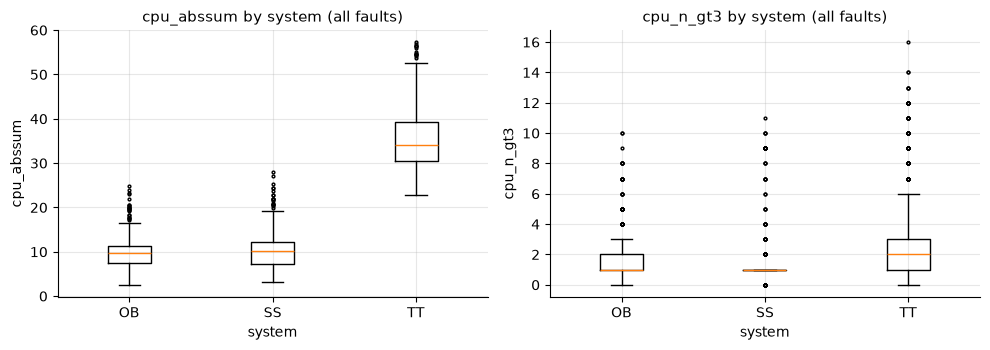

In [25]:
cpu_cases = features[features["fault"] == "cpu"]
display(
    cpu_cases.groupby("system")[["cpu_max", "mem_max", "latency_max", "cpu_abssum"]]
    .median()
    .rename(index=SYSTEM_NAMES)
    .round(2)
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, column in zip(axes, ["cpu_abssum", "cpu_n_gt3"], strict=True):
    ax.boxplot(
        [features.loc[features["system"] == s, column] for s in SYSTEM_NAMES],
        tick_labels=list(SYSTEM_NAMES.values()),
        flierprops={"ms": 2},
    )
    ax.set_xlabel("system")
    ax.set_ylabel(column)
    ax.set_title(f"{column} by system (all faults)")
plt.tight_layout()
plt.show()

The same fault looks different in each system. For `cpu` faults the median `cpu_max` is 4.7 (OB), 6.1 (SS) and 4.0 (TT), and the memory shift is 2.7, 4.2 and 1.0. The count-type features also grow with system size: the median `cpu_abssum` is about 10 in OB and SS and about 34 in TT, which has 68 services against 11 in OB and in SS after the `-db` merge (15 before it). A model trained on two systems may therefore not transfer to the third. The go/no-go spike measured this gap (spec §5.3); plan line 7 re-measures it with leave-one-system-out and tests `--norm-counts`, which replaces the sum and count with a per-service mean and fraction.

### 3.2 EDA summary

What this EDA tells us, and what it hands to the modeling section:

- **Data:** 270 cases (45 per fault, 15 per fault per system) give 1,350 rows of 42 features. No case is skipped. The quirks are handled in `faulttrack.data`.
- **Signatures:** CPU, memory and latency shifts separate most faults. The two pairs that look hardest to tell apart are `mem` vs `disk` and `delay` vs `loss`; the confusion matrix will show whether that holds.
- **Telemetry gaps:** `diskio` is present on only 6 of 11 OB services and 7 of 11 SS services in the disk-fault cases (median), so disk faults there look like memory faults. `error` almost never shifts and carries almost no information.
- **Scaling:** the scale floor and log compression keep near-constant metrics from dominating (2.7).
- **Importance:** memory features have the most mutual information, and few features are redundant.
- **Systems differ** in size (11, 15 and 68 services; SS has 11 after merging each service with its `-db`) and in the size of the same fault's shift, which motivates the unseen-system analysis in plan line 7.
- **Next (sections 4–7):** compare the dummy, rule, logistic regression, decision tree, random forest and XGBoost models with CV grouped by `case_id` (5 windows per case), report macro F1 as mean ± std (min/max) across folds, and tune with the same grouped folds.

## 4. Models

We compare six classifiers on the same folds. All model definitions live in `src/faulttrack/models.py`, so `train.py` uses exactly what is scored here:

| Model | Role |
|---|---|
| Dummy (`most_frequent`) | the floor: always predicts the most common class in the training fold |
| Rule (`RuleBaseline`) | no ML: the metric kind with the biggest shift wins (largest `abs(<kind>_max)`; `cpu`→cpu, `mem`→mem, `diskio`→disk, `socket`→socket, `latency` and `workload`→delay, `error`→loss) |
| Logistic regression | linear: `StandardScaler` + `LogisticRegression` in a `Pipeline`, so the scaler is fit inside each training fold |
| Decision tree | a single tree, the basis of the on-call runbook in 6.6 |
| Random forest | bagged trees |
| XGBoost | gradient-boosted trees |

**How they are scored.** `faulttrack.evaluation.grouped_cv`: 5-fold `GroupKFold` with `groups=case_id` (groups shuffled with seed 42), so the 5 detection-delay rows of a case are always on the same side of a split. A random row-level split would put near-identical windows of one incident in both train and test and overstate the score. Every model uses `random_state=42`. Macro F1 is reported as **mean ± std (min/max) across the 5 folds**: with 45 cases per class, a single pooled score would hide how much the result moves between folds. In this section the models use library defaults; section 5 tunes them.

In [26]:
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree

from faulttrack.evaluation import (
    LABELS,
    CVResult,
    grouped_cv,
    grouped_permutation_importance,
    grouped_splits,
    suspect_hit_rate,
)
from faulttrack.models import (
    FINAL_MODEL_NAME,
    FINAL_PARAMS,
    candidate_models,
    final_model,
    param_grids,
    tuned_search,
)

MODEL_NAMES = {
    "dummy": "Dummy (most frequent)",
    "rule": "Rule (biggest shift wins)",
    "logreg": "Logistic regression",
    "tree": "Decision tree",
    "forest": "Random forest",
    "xgboost": "XGBoost",
}
X_all = features[FEATURE_NAMES]
y_all = np.array([LABELS.index(fault) for fault in features["fault"]])


# One table row: macro F1 mean ± std (min/max) across folds, plus accuracy.
def cv_row(result: CVResult) -> dict[str, Any]:
    return {
        "macro F1 (mean ± std)": f"{result.mean:.3f} ± {result.std:.3f}",
        "min": round(result.min, 3),
        "max": round(result.max, 3),
        "accuracy (mean ± std)": f"{result.accuracy_mean:.3f} ± {result.accuracy_std:.3f}",
    }


untuned = {
    name: grouped_cv(model, features) for name, model in candidate_models().items()
}
display(
    pd.DataFrame({MODEL_NAMES[n]: cv_row(r) for n, r in untuned.items()}).T.rename_axis(
        "model (untuned)"
    )
)

,macro F1 (mean ± std),min,max,accuracy (mean ± std)
model (untuned),,,,
Dummy (most frequent),0.030 ± 0.002,0.028,0.033,0.100 ± 0.009
Rule (biggest shift wins),0.277 ± 0.038,0.212,0.318,0.369 ± 0.046
Logistic regression,0.724 ± 0.027,0.691,0.767,0.730 ± 0.033
Decision tree,0.663 ± 0.046,0.593,0.714,0.676 ± 0.039
Random forest,0.800 ± 0.026,0.776,0.846,0.809 ± 0.022
XGBoost,0.773 ± 0.020,0.746,0.797,0.781 ± 0.023


Untuned models on grouped 5-fold CV. The random forest is best (macro F1 **0.800 ± 0.026**, min 0.776, max 0.846), the same number as the sanity check in #7, ahead of XGBoost (0.773 ± 0.020) and logistic regression (0.724 ± 0.027). The single decision tree is 0.663 ± 0.046.

The baselines show how much the model adds. The dummy scores 0.030: it predicts the class most common in the training fold, which is the class *least* common in the test fold, since the classes are exactly balanced overall. The rule scores only 0.277 ± 0.038, because one kind's largest shift is a poor fault label on its own. Latency rises for almost every fault (section 2.5), so the rule calls 759 of the 1,350 rows `delay`. It never predicts `loss`, because `error` is rarely exported. It also almost never says `socket` (6 rows): in socket faults the suspect service's CPU shift (median 4.52) is larger than its socket shift (1.74).

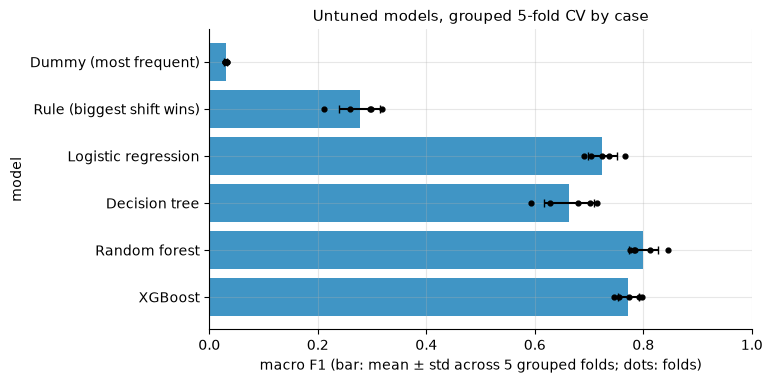

In [27]:
# Mean macro F1 per model, with the 5 fold scores as dots.
def plot_scores(results: dict[str, CVResult], title: str) -> None:
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(results) + 1.2))
    names = list(results)[::-1]
    means = [results[n].mean for n in names]
    stds = [results[n].std for n in names]
    y_pos = np.arange(len(names))
    ax.barh(y_pos, means, xerr=stds, color="#0072B2", alpha=0.75, capsize=3)
    for k, n in enumerate(names):
        ax.scatter(
            results[n].fold_macro_f1,
            np.full(results[n].n_folds, k),
            color="black",
            s=12,
            zorder=3,
        )
    ax.set_yticks(y_pos, [MODEL_NAMES[n] for n in names])
    ax.set_xlim(0, 1)
    ax.set_xlabel("macro F1 (bar: mean ± std across 5 grouped folds; dots: folds)")
    ax.set_ylabel("model")
    ax.set_title(title)
    plt.show()


plot_scores(untuned, "Untuned models, grouped 5-fold CV by case")

The same scores as a chart: bars are the mean macro F1, error bars one std, and dots the 5 folds. The tree models' folds overlap: the best random forest fold (0.846) is well above the best XGBoost fold (0.797), but the worst folds are close (0.776 and 0.746).

## 5. Tuning

Each tunable model gets a small grid (13–36 combinations), searched with `GridSearchCV(cv=GroupKFold(5), scoring="f1_macro")`, built by `faulttrack.models.tuned_search`.

**Scores come from nested grouped CV.** Scoring a model with the same folds that picked its hyperparameters makes it look better than it is. So we hand the whole search to `grouped_cv`: for each of the 5 outer folds, the search is cloned and fit on the outer training cases only, with `groups=` set to their `case_id` (`grouped_cv` passes it to any `GridSearchCV` or `RandomizedSearchCV`). The inner `GroupKFold(5)` then splits only those cases, picks the best grid point, refits on the whole outer training fold, and the outer test fold, made of cases the search never saw, scores it. A unit test (`tests/test_evaluation.py::test_nested_search_never_sees_an_outer_test_case`) checks that no fit inside the search ever sees an outer-test `case_id`.

XGBoost's early stopping (spec 5.1) isn't used: the grid tunes `n_estimators` directly, which keeps the search plain `GridSearchCV` and needs no extra validation split inside each fold.

In [28]:
grids = pd.DataFrame(
    [
        {
            "model": MODEL_NAMES[name],
            "parameter": param.removeprefix("model__"),
            "values": ", ".join(
                f"{v:.3g}" if isinstance(v, float) else str(v) for v in values
            ),
            "combinations": int(np.prod([len(v) for v in grid.values()])),
        }
        for name, grid in param_grids().items()
        for param, values in grid.items()
    ]
).set_index(["model", "parameter"])
display(grids)

values  \
model               parameter                                                             
Logistic regression C                 0.001, 0.00316, 0.01, 0.0316, 0.1, 0.316, 1, 3...   
Decision tree       max_depth                                2, 3, 4, 5, 6, 8, 10, None   
                    min_samples_leaf                                       1, 5, 10, 20   
Random forest       n_estimators                                               200, 500   
                    max_depth                                               None, 8, 16   
                    min_samples_leaf                                        1, 2, 5, 10   
XGBoost             learning_rate                                        0.05, 0.1, 0.3   
                    max_depth                                                   3, 5, 7   
                    min_child_weight                                               1, 5   
                    n_estimators                                               100, 300   

                                      combinations  
model               parameter                       
Logistic regression C                           13  
Decision tree       max_depth                   32  
                    min_samples_leaf            32  
Random forest       n_estimators                24  
                    max_depth                   24  
                    min_samples_leaf            24  
XGBoost             learning_rate               36  
                    max_depth                   36  
                    min_child_weight            36  
                    n_estimators                36

The grids. `C` is the inverse regularization strength of logistic regression (13 values from 0.001 to 1000, log-spaced). The tree grid includes depth 3–4, the runbook depths. `combinations` is the size of each model's whole grid.

In [29]:
# Nested grouped CV: grouped_cv clones the search per outer fold and passes the
# training fold's case_id as groups=, so GroupKFold(5) inside the search only
# splits outer-training cases. This cell takes a few minutes.
nested = {name: grouped_cv(tuned_search(name), features) for name in param_grids()}
tuned_table = pd.DataFrame(
    {
        MODEL_NAMES[n]: {
            **cv_row(r),
            "untuned mean": round(untuned[n].mean, 3),
            "change": f"{r.mean - untuned[n].mean:+.3f}",
        }
        for n, r in nested.items()
    }
).T.rename_axis("model (tuned, nested CV)")
display(tuned_table)

,macro F1 (mean ± std),min,max,accuracy (mean ± std),untuned mean,change
"model (tuned, nested CV)",,,,,,
Logistic regression,0.724 ± 0.024,0.691,0.754,0.730 ± 0.029,0.724,+0.000
Decision tree,0.676 ± 0.049,0.6,0.741,0.687 ± 0.046,0.663,+0.012
Random forest,0.800 ± 0.030,0.778,0.859,0.809 ± 0.024,0.8,-0.001
XGBoost,0.772 ± 0.018,0.757,0.803,0.780 ± 0.018,0.773,-0.001


Tuned models, scored with nested grouped CV, next to their untuned means. **Tuning changes almost nothing:** the random forest goes from 0.800 to 0.800 ± 0.030 (min 0.778, max 0.859), XGBoost from 0.773 to 0.772 ± 0.018, logistic regression stays at 0.724 ± 0.024, and the decision tree gains the most, 0.663 → 0.676 ± 0.049. Every change is far smaller than the fold std. The library defaults were already near the best these grids offer; the earlier finding that scaling the features mattered more than the model choice (section 2.7) holds here too.

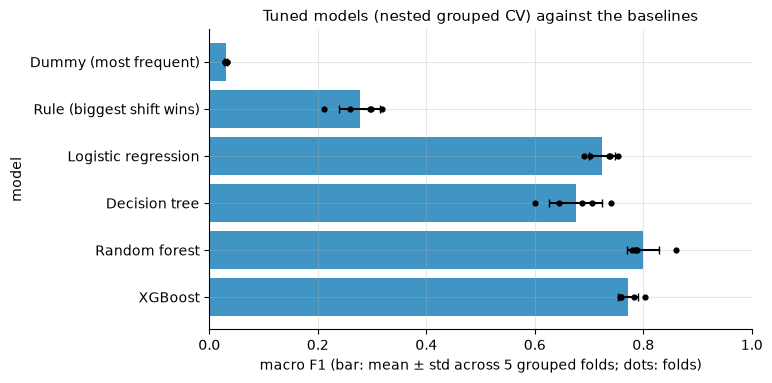

In [30]:
plot_scores(
    {**{n: untuned[n] for n in ("dummy", "rule")}, **nested},
    "Tuned models (nested grouped CV) against the baselines",
)

The tuned models against the two baselines (bars: mean ± std across the 5 outer folds; dots: folds).

**Hyperparameters for the final model.** Nested CV scores the *tuning procedure*; each outer fold may pick different hyperparameters. To fix one set for `final_model()`, we run the same searches once on the whole table, on the same case-grouped folds as `grouped_cv` (`cv=list(grouped_splits(features))`). This is the only place the notebook tunes on the whole table. Its best score is optimistic, because the same folds choose and score the hyperparameters, so the selection in section 6 uses the nested scores instead.

In [31]:
# Whole-table tuning: the same grids, on the same case-grouped folds as
# grouped_cv (cv=list(grouped_splits(...))). These are the hyperparameters a
# final model is fit with; their best_score_ is optimistic (the folds that
# chose them also score them), so model selection uses the nested scores above.
whole = {
    name: tuned_search(name, cv=list(grouped_splits(features))).fit(X_all, y_all)
    for name in param_grids()
}
display(
    pd.DataFrame(
        {
            MODEL_NAMES[n]: {
                "best parameters": {
                    k.removeprefix("model__"): (
                        round(v, 4) if isinstance(v, float) else v
                    )
                    for k, v in s.best_params_.items()
                },
                "grouped CV macro F1 of the best (optimistic)": round(s.best_score_, 3),
                "nested macro F1": round(nested[n].mean, 3),
            }
            for n, s in whole.items()
        }
    ).T.rename_axis("model")
)

,best parameters,grouped CV macro F1 of the best (optimistic),nested macro F1
model,,,
Logistic regression,{'C': 0.3162},0.73,0.724
Decision tree,"{'max_depth': 6, 'min_samples_leaf': 1}",0.708,0.676
Random forest,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",0.799,0.8
XGBoost,"{'learning_rate': 0.1, 'max_depth': 5, 'min_ch...",0.786,0.772


Whole-table tuning results. The best scores here (0.799 for the random forest) are within 0.02 of the nested ones, so the optimism is small for every model but the decision tree (0.708 against 0.676 nested).

## 6. Final model

**Selection rule (fixed before looking at the results):** take the highest nested mean macro F1. If a simpler model's mean is within one fold std of the best, prefer the simpler one. Simplest first: logistic regression, decision tree, random forest, XGBoost. The next cell applies the rule and checks that `faulttrack.models.final_model()` holds the same model with the whole-table hyperparameters.

In [32]:
# The selection rule: highest nested mean macro F1; any simpler model within one
# fold std of the best wins instead (models are listed simplest first).
best = max(nested, key=lambda n: nested[n].mean)
threshold = nested[best].mean - nested[best].std
chosen = next(n for n in nested if nested[n].mean >= threshold)
print(f"best nested mean: {MODEL_NAMES[best]} {nested[best].summary()}")
print(f"within one std (>= {threshold:.3f}): ", end="")
print(", ".join(MODEL_NAMES[n] for n in nested if nested[n].mean >= threshold))
print(f"chosen: {MODEL_NAMES[chosen]}")

# faulttrack.models.final_model() must be this choice with the whole-table params
assert chosen == FINAL_MODEL_NAME, (chosen, FINAL_MODEL_NAME)
assert FINAL_PARAMS == whole[chosen].best_params_, (
    FINAL_PARAMS,
    whole[chosen].best_params_,
)
print(f"final_model() = {MODEL_NAMES[FINAL_MODEL_NAME]} with {FINAL_PARAMS}")

best nested mean: Random forest macro F1 0.800 ± 0.030 (min 0.778, max 0.859)
within one std (>= 0.769): Random forest, XGBoost
chosen: Random forest
final_model() = Random forest with {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}


**Choice: random forest** with `n_estimators=200`, `max_depth=None`, `min_samples_leaf=2` (and `random_state=42`).

- It has the highest nested mean, 0.800 ± 0.030.
- The only other model within one std is XGBoost (0.772 ± 0.018), which is more complex, so the tie-break also points to the random forest. Logistic regression (0.724) and the decision tree (0.676) are more than one std behind.
- XGBoost has the smaller fold spread, but its mean is 0.028 lower and its best fold (0.803) is below the forest's mean. A reasonable alternative, not a better one.
- The forest also has fewer hyperparameters that matter and is less sensitive to them (it barely moved under tuning), which suits a model that `train.py` refits without supervision.

The choice and its numbers are recorded in `docs/decisions.md`.

In [33]:
final = grouped_cv(final_model(), features)
print(f"final_model(), grouped 5-fold CV (seed 42): {final.summary()}")
print(f"  accuracy {final.accuracy_mean:.3f} ± {final.accuracy_std:.3f}")
print(f"  folds: {', '.join(f'{v:.3f}' for v in final.fold_macro_f1)}")
print(
    f"nested CV of the same search:              {nested[FINAL_MODEL_NAME].summary()}"
)

final_model(), grouped 5-fold CV (seed 42): macro F1 0.799 ± 0.028 (min 0.775, max 0.850)
  accuracy 0.807 ± 0.025
  folds: 0.850, 0.775, 0.810, 0.778, 0.783
nested CV of the same search:              macro F1 0.800 ± 0.030 (min 0.778, max 0.859)


**Final model, grouped 5-fold CV: macro F1 0.799 ± 0.028 (min 0.775, max 0.850), accuracy 0.807 ± 0.025.** This is `grouped_cv(final_model(), features)`, the number `train.py` will reproduce. Its hyperparameters were chosen on these same folds, so the unbiased estimate is the nested score of the search, 0.800 ± 0.030; the two agree to 0.001. The rest of section 6 uses the `final_model()` out-of-fold predictions.

In [34]:
seeds = range(5)
by_seed = {seed: grouped_cv(final_model(), features, seed=seed) for seed in seeds}
seed_table = pd.DataFrame(
    {f"fold seed {s}": cv_row(r) for s, r in by_seed.items()}
).T.rename_axis("grouped_cv seed")
display(seed_table)
seed_means = np.array([r.mean for r in by_seed.values()])
print(
    f"mean of the 5 means {seed_means.mean():.3f}, range {seed_means.min():.3f} to "
    f"{seed_means.max():.3f} ({seed_means.max() - seed_means.min():.3f} wide); "
    f"headline (seed 42) {final.mean:.3f}"
)

,macro F1 (mean ± std),min,max,accuracy (mean ± std)
grouped_cv seed,,,,
fold seed 0,0.787 ± 0.044,0.709,0.837,0.792 ± 0.033
fold seed 1,0.803 ± 0.064,0.676,0.849,0.807 ± 0.059
fold seed 2,0.823 ± 0.047,0.743,0.873,0.820 ± 0.049
fold seed 3,0.797 ± 0.051,0.735,0.852,0.803 ± 0.050
fold seed 4,0.803 ± 0.022,0.769,0.832,0.809 ± 0.022


mean of the 5 means 0.803, range 0.787 to 0.823 (0.036 wide); headline (seed 42) 0.799


**How much the headline depends on the fold assignment.** `grouped_cv` shuffles cases into folds with a seed (42 everywhere in this project). Re-running the final model with fold seeds 0–4 gives means from 0.787 to 0.823 (mean of the 5 means 0.803, a range 0.036 wide), and single folds from 0.676 to 0.873. The seed-42 headline, 0.799, is in the middle of that range. So the second decimal of the headline is uncertain, and differences between models smaller than about 0.03 should not be read as real. The headline stays seed 42; this table only shows how far it can move.

### 6.1 Per-class metrics

Precision, recall and F1 per fault, on the pooled out-of-fold predictions of the final model (each of the 1,350 rows is predicted once, by the model that didn't train on its case).

In [35]:
per_class = pd.DataFrame(final.per_class).T
per_class["support"] = per_class["support"].astype(int)
display(per_class.round(3).rename_axis("fault"))

,precision,recall,f1,support
fault,,,,
cpu,0.761,0.822,0.791,225
mem,0.916,0.916,0.916,225
disk,0.961,0.880,0.919,225
socket,0.750,0.760,0.755,225
delay,0.756,0.742,0.749,225
loss,0.718,0.724,0.721,225


Memory and disk faults are the easiest (F1 0.916 and 0.919), and disk has the highest precision (0.961): when the model says disk, it's almost always right. The four others sit between 0.72 and 0.79, with `loss` lowest (0.721). The confusion matrix shows where those errors go.

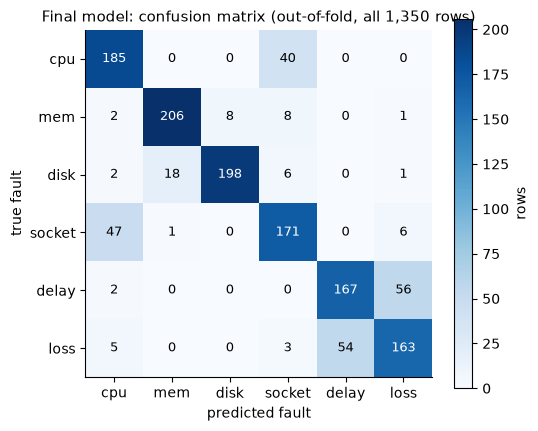

In [36]:
cm = final.confusion
fig, ax = plt.subplots(figsize=(5.6, 4.8))
image = ax.imshow(cm, cmap="Blues")
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
            fontsize=9,
        )
ax.set_xticks(range(len(LABELS)), list(LABELS))
ax.set_yticks(range(len(LABELS)), list(LABELS))
ax.grid(False)
ax.set_xlabel("predicted fault")
ax.set_ylabel("true fault")
ax.set_title("Final model: confusion matrix (out-of-fold, all 1,350 rows)")
fig.colorbar(image, ax=ax, label="rows")
plt.show()

### 6.2 Confusion matrix

Out-of-fold confusion matrix of the final model (rows: true fault; columns: predicted). **The main confusions come in two pairs:**

- **delay vs. loss**, as expected: 56 delay rows predicted as loss and 54 loss rows as delay. Both faults mainly show up as latency, and `error`, the one kind that could tell packet loss from delay, is exported by so few services that its features carry no information (they score 0 in the permutation importance in 6.5).
- **cpu vs. socket**: 40 cpu rows predicted as socket and 47 socket rows as cpu. A socket fault in these systems also raises CPU on the suspect service (median `top_cpu` 4.52 for socket faults, 5.00 for cpu faults), so the two differ mostly in the size of the socket shift (median `top_socket` 1.74 against 1.11).

The third, smaller one is **disk predicted as memory** (18 rows): the disk telemetry gap from section 2.3, where disk stress shows up as page-cache memory in services without `diskio`. Outside these three pairs, no cell has more than 8 rows: the model rarely mixes up the resource faults (cpu, mem, disk, socket) with the network faults (delay, loss).

,one-vs-rest ROC AUC (pooled out-of-fold)
cpu,0.976
mem,0.985
disk,0.992
socket,0.971
delay,0.968
loss,0.951
macro,0.974


macro ROC AUC per fold: 0.975 ± 0.005 (min 0.969, max 0.982)


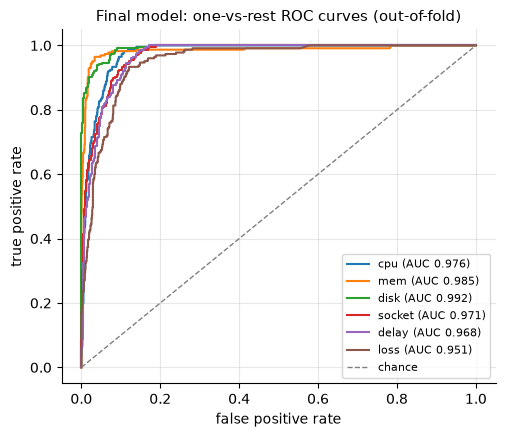

In [37]:
assert final.y_proba is not None and final.fold is not None
auc = final.roc_auc_ovr
assert auc is not None
fold_auc = [
    float(
        np.mean(
            [
                roc_auc_score(
                    final.y_true[final.fold == k] == label,
                    final.y_proba[final.fold == k, i],
                )
                for i, label in enumerate(LABELS)
            ]
        )
    )
    for k in range(final.n_folds)
]
display(
    pd.Series(auc, name="one-vs-rest ROC AUC (pooled out-of-fold)").round(3).to_frame()
)
print(
    f"macro ROC AUC per fold: {np.mean(fold_auc):.3f} ± {np.std(fold_auc):.3f} (min {min(fold_auc):.3f}, max {max(fold_auc):.3f})"
)

fig, ax = plt.subplots(figsize=(5.6, 4.6))
for i, label in enumerate(LABELS):
    fpr, tpr, _ = roc_curve(final.y_true == label, final.y_proba[:, i])
    ax.plot(fpr, tpr, label=f"{label} (AUC {auc[label]:.3f})")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1, label="chance")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("Final model: one-vs-rest ROC curves (out-of-fold)")
ax.legend(fontsize=8, loc="lower right")
plt.show()

### 6.3 One-vs-rest ROC AUC

One-vs-rest ROC AUC from the out-of-fold class probabilities: for each fault, how well the predicted probability ranks rows of that fault above all other rows. Pooled macro AUC is **0.974** (per fold 0.975 ± 0.005, min 0.969, max 0.982). Every class is above 0.95; `loss` is lowest (0.951). AUC is much higher than macro F1 because it only measures ranking: the true fault usually gets a high probability even when, as for delay vs. loss, a neighbor gets a slightly higher one.

,mean,std,min,max
detection delay (s),,,,
0,0.787,0.049,0.746,0.857
30,0.797,0.051,0.744,0.893
60,0.805,0.053,0.727,0.893
90,0.797,0.023,0.771,0.840
120,0.806,0.034,0.777,0.870


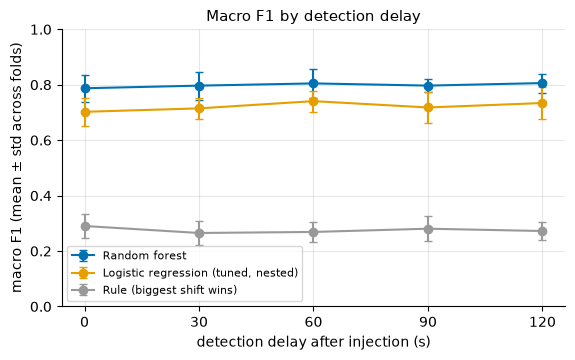

In [38]:
delay = pd.DataFrame(final.delay_summary()).T.rename_axis("detection delay (s)")
display(delay.round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for name, result, color in (
    (MODEL_NAMES[FINAL_MODEL_NAME], final, "#0072B2"),
    (MODEL_NAMES["logreg"] + " (tuned, nested)", nested["logreg"], "#E69F00"),
    (MODEL_NAMES["rule"], untuned["rule"], "#999999"),
):
    summary = pd.DataFrame(result.delay_summary()).T
    ax.errorbar(
        summary.index,
        summary["mean"],
        yerr=summary["std"],
        marker="o",
        capsize=3,
        label=name,
        color=color,
    )
ax.set_xticks(list(DELAYS_S))
ax.set_ylim(0, 1)
ax.set_xlabel("detection delay after injection (s)")
ax.set_ylabel("macro F1 (mean ± std across folds)")
ax.set_title("Macro F1 by detection delay")
ax.legend(fontsize=8, loc="lower left")
plt.show()

### 6.4 Macro F1 by detection delay

Macro F1 of the final model by detection delay (mean ± std across folds), next to tuned logistic regression and the rule. The forest stays between 0.787 (0 s) and 0.806 (120 s) at every delay, with overlapping fold spreads, so it doesn't depend on catching the fault at the moment of injection. That matters in practice, because a real alert fires some time after the fault starts. The shifts shrink a little as the delay grows (section 2.5), but the model is trained on all five delays and keeps up.

### 6.5 Feature importance

Two views. **Built-in importance** comes from the model's own fit on all rows: impurity decrease for the random forest, and gain for the tuned XGBoost (spec 5.2 asks for XGBoost gain even though it isn't the final model). **Permutation importance** measures the drop in out-of-fold macro F1 when one feature is shuffled, so it reflects only what generalizes to unseen cases.

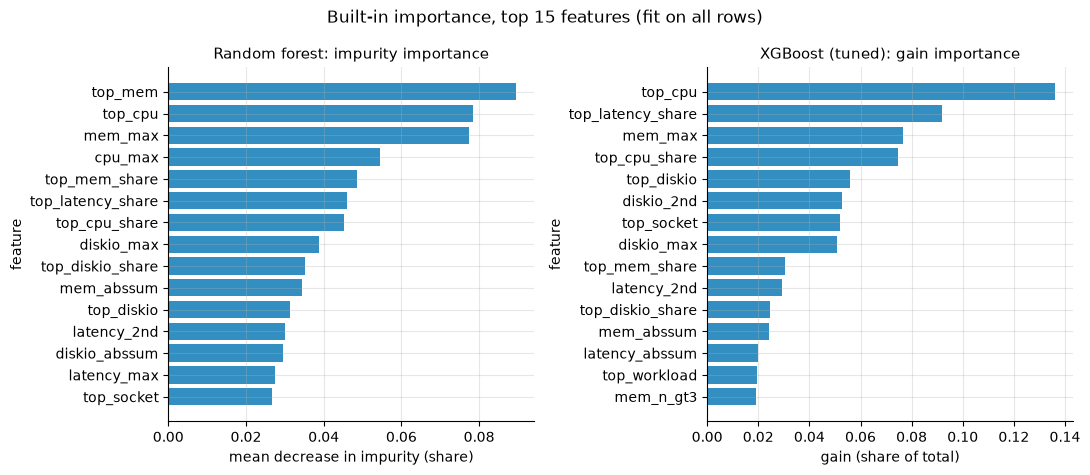

In [39]:
fitted_final = final_model().fit(X_all, y_all)
builtin = pd.Series(fitted_final.feature_importances_, index=FEATURE_NAMES)
xgb_fitted = whole["xgboost"].best_estimator_  # refit on all rows with its tuned params
gain = pd.Series(xgb_fitted.get_booster().get_score(importance_type="gain")).reindex(
    FEATURE_NAMES, fill_value=0.0
)
gain = gain / gain.sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
panels: list[tuple[Any, pd.Series, str, str]] = [
    (
        axes[0],
        builtin,
        f"{MODEL_NAMES[FINAL_MODEL_NAME]}: impurity importance",
        "mean decrease in impurity (share)",
    ),
    (axes[1], gain, "XGBoost (tuned): gain importance", "gain (share of total)"),
]
for ax, values, title, xlabel in panels:
    top = values.sort_values(ascending=False).head(15).iloc[::-1]
    ax.barh(top.index, top.to_numpy(), color="#0072B2", alpha=0.8)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("feature")
fig.suptitle("Built-in importance, top 15 features (fit on all rows)")
fig.tight_layout()
plt.show()

Top 15 features by built-in importance. Both models lean on the suspect service's profile (`top_<kind>`, `top_<kind>_share`) and on the memory and CPU maxima: the forest ranks `top_mem` (0.090), `top_cpu` (0.078) and `mem_max` (0.077) first, XGBoost `top_cpu`, `top_latency_share` and `mem_max`. That matches the mutual information in section 3, where memory and CPU carried the most information. No single feature dominates: the forest's top feature has only 9% of the total.

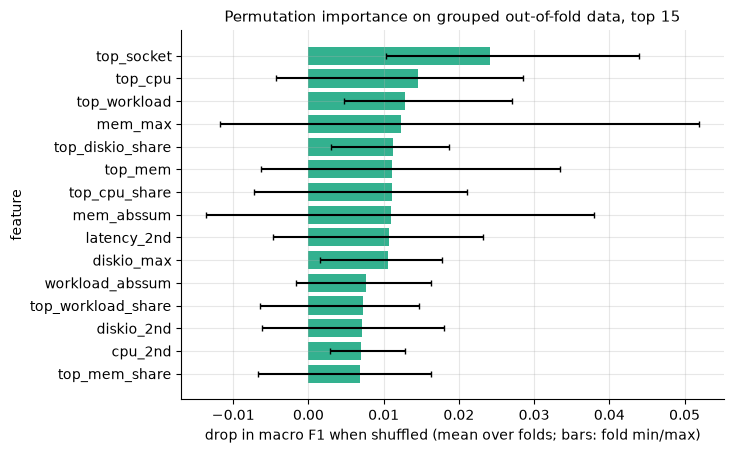

features with mean drop <= 0: 7 of 42


In [40]:
perm = grouped_permutation_importance(final_model(), features, n_repeats=10)
top = perm.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(top.index, top["mean"], color="#009E73", alpha=0.8)
ax.errorbar(
    top["mean"],
    np.arange(len(top)),
    xerr=[top["mean"] - top["min"], top["max"] - top["mean"]],
    fmt="none",
    color="black",
    capsize=2,
)
ax.set_xlabel("drop in macro F1 when shuffled (mean over folds; bars: fold min/max)")
ax.set_ylabel("feature")
ax.set_title("Permutation importance on grouped out-of-fold data, top 15")
plt.show()
print(
    f"features with mean drop <= 0: {int((perm['mean'].to_numpy() <= 0).sum())} of {len(perm)}"
)

Permutation importance of the final model on grouped out-of-fold data (5 folds, 10 shuffles per feature and fold, `random_state=42`; bars are the fold min/max). The drops are small, at most 0.024 macro F1 (`top_socket`), because the features overlap: shuffling `mem_max` still leaves `top_mem` and `mem_abssum`. The order also differs from the built-in importance: `top_socket` is first out of fold although it is only 15th by impurity, because it is what separates socket from cpu faults (6.2). The seven `error_*` and `top_error*` features have exactly 0 importance, which confirms section 2.3: `error` is almost never exported. They stay in the feature set because the feature definitions are shared with the API and fixed for this release.

depth-3 tree, grouped 5-fold CV: macro F1 0.570 ± 0.067 (min 0.455, max 0.638)


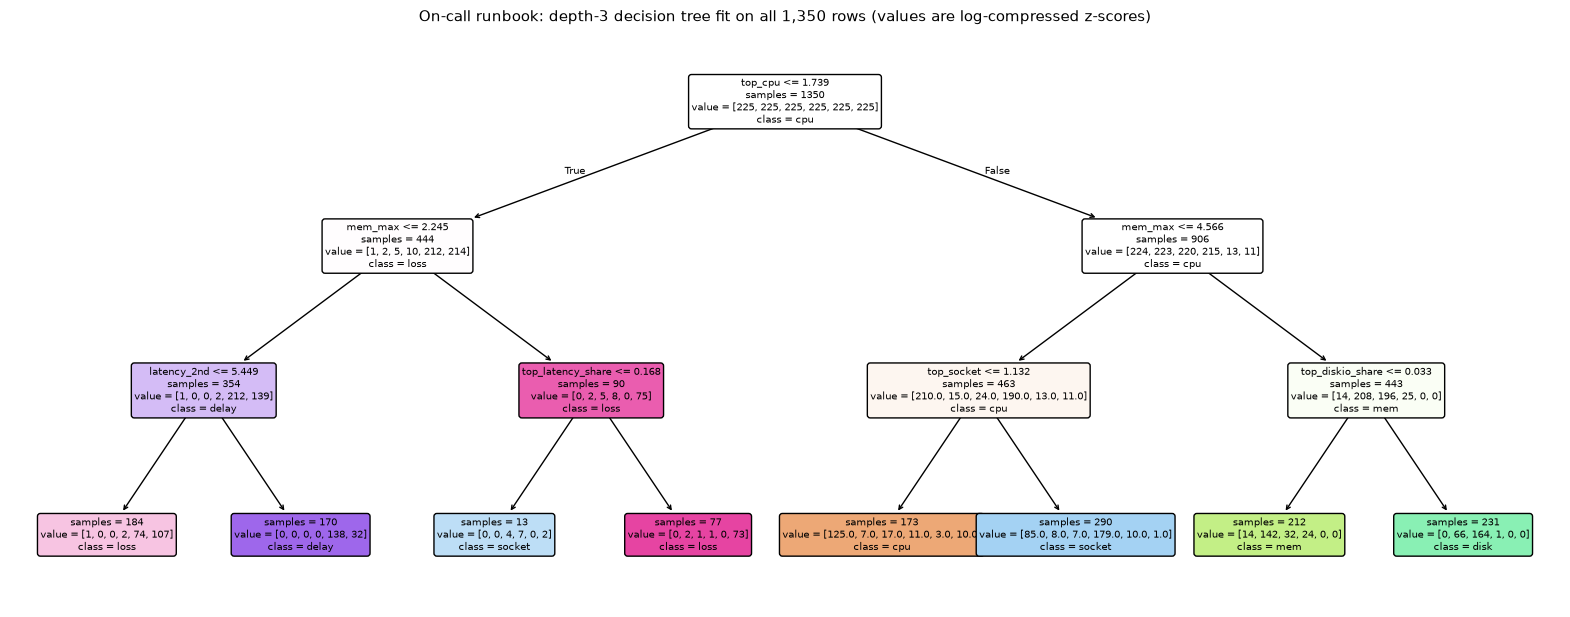

In [41]:
runbook_model = DecisionTreeClassifier(max_depth=3, random_state=SEED)
runbook_cv = grouped_cv(runbook_model, features)
print(f"depth-3 tree, grouped 5-fold CV: {runbook_cv.summary()}")
runbook = runbook_model.fit(X_all, y_all)
fig, ax = plt.subplots(figsize=(20, 7.5))
plot_tree(
    runbook,
    feature_names=FEATURE_NAMES,
    class_names=list(LABELS),
    filled=True,
    rounded=True,
    impurity=False,
    proportion=False,
    fontsize=7,
    ax=ax,
)
ax.set_title(
    "On-call runbook: depth-3 decision tree fit on all 1,350 rows (values are log-compressed z-scores)"
)
plt.show()

### 6.6 On-call runbook: a depth-3 decision tree

A tree with three questions can be read as a runbook. It's fit on all rows for display, and it is much weaker than the final model: **0.570 ± 0.067** macro F1 on grouped CV, against 0.799. In words:

1. **Did the most-shifted service's CPU rise clearly (`top_cpu` > 1.74, about 4.7 in raw z)?**
   - **No:** the fault is network-like. If memory barely moved anywhere (`mem_max` ≤ 2.24), a strong second latency shift (`latency_2nd` > 5.45) means `delay`, otherwise `loss`. If memory did move, the latency share of the suspect service separates `socket` from `loss`.
   - **Yes:** a resource fault. If memory rose only moderately (`mem_max` ≤ 4.57), a socket shift on the suspect service (`top_socket` > 1.13) means `socket`, otherwise `cpu`. If memory rose strongly, any `diskio` share on the suspect service (`top_diskio_share` > 0.03) means `disk`, otherwise `mem`.

It makes the same confusions as the forest, only more often: in the leaves, cpu and socket share a branch, and so do delay and loss.

In [42]:
hit_rows = suspect_hit_rate(features)
two_answers = pd.DataFrame(
    {
        "fault (which kind)": {
            "source": "model",
            "metric": "macro F1, grouped 5-fold CV (mean ± std)",
            "value": f"{final.mean:.3f} ± {final.std:.3f}",
        },
        "suspect_service (where)": {
            "source": "rule (most-anomalous service, no ML)",
            "metric": "hit rate per alert window, all 1,350 rows",
            "value": f"{hit_rows:.3f}",
        },
    }
).T
display(two_answers)
by_system = features.groupby("system").apply(suspect_hit_rate, include_groups=False)
display(short_names(by_system.to_frame("suspect hit rate (rule)")).round(3).T)

,source,metric,value
fault (which kind),model,"macro F1, grouped 5-fold CV (mean ± std)",0.799 ± 0.028
suspect_service (where),"rule (most-anomalous service, no ML)","hit rate per alert window, all 1,350 rows",0.900


,OB,SS,TT
suspect hit rate (rule),0.88,0.973,0.847


### 6.7 The second answer: suspect service (a rule, not a model)

FaultTrack's other answer, *which service did it start in*, doesn't come from the classifier. It's the most-anomalous-service rule: the service with the largest total shift across kinds (`features.suspect_service`). The two answers are reported separately, each with its own metric: the classifier's macro F1 for `fault`, and the rule's hit rate (the share of alert windows where the suspect is the injected service, with a service and its `-db` counted as one) for `suspect_service`. The rule names the right service in **0.900** of the 1,350 windows: 0.880 in OB, 0.973 in SS and 0.847 in TT. It needs no training, so it has no folds; the hit rate is over all rows.

## 7. Summary of the modeling

- **Final model:** random forest (`n_estimators=200`, `max_depth=None`, `min_samples_leaf=2`, `random_state=42`), from `faulttrack.models.final_model()`.
- **Headline:** macro F1 **0.799 ± 0.028** (min 0.775, max 0.850) on grouped 5-fold CV across all three systems; nested CV of the tuning gives 0.800 ± 0.030. Over fold seeds 0–4 the mean moves between 0.787 and 0.823.
- **Baselines:** the dummy scores 0.030 and the biggest-shift rule 0.277, so the model adds a lot over both.
- **Model comparison (nested):** random forest 0.800 > XGBoost 0.772 > logistic regression 0.724 > decision tree 0.676. Tuning changed no model by more than 0.013.
- **Errors:** delay vs. loss (about 55 rows each way) and cpu vs. socket (40 and 47), then disk read as memory (18). ROC AUC is 0.974 macro, and macro F1 stays between 0.787 and 0.806 for every detection delay from 0 to 120 s.
- **Suspect service:** the rule's hit rate is 0.900, reported apart from the model.
- **Not covered here:** how the model does on a system it has never seen (leave-one-system-out) is the next section, plan line 7. The headline mixes all three systems in training and testing.